# ARTE4110U Challenge: Initialization and Gradient Flow
**Name:** Joao Pedro Minari &emsp; **Student ID:** [removed]

Investigate how initialization can prevent a deep network from learning, then propose and test a repair. Use **PyTorch autograd for all gradients**. No hand calculations or manual gradient implementations are required.

Complete the TODOs and short answers, then submit this notebook individually on Canvas with its outputs. Most model, diagnostic, initialization, and training code is yours to write.


## 1. Data and model

Use the real handwritten-digits dataset: 1,797 images of size 8 × 8, labeled 0–9. The supplied code scales pixels to `[0, 1]` and creates fixed training, validation, and test sets. Scikit-learn is used only for loading and splitting data. A CPU is sufficient.

Keep the settings unchanged throughout the comparison.


In [1]:
# Uncomment only if packages are missing:
# %pip install torch scikit-learn matplotlib numpy

import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.set_num_threads(2)  # Small CPU experiments can be slower with many threads.

SPLIT_SEED = 42
ORDER_SEED = 31415
SEED = 0
BATCH_SIZE = 64
WIDTH = 64
N_HIDDEN = 12
EPOCHS = 25
LR = 0.01
MOMENTUM = 0.9

digits = load_digits()
indices = np.arange(len(digits.target))
train_idx, holdout_idx = train_test_split(
    indices, test_size=0.40, random_state=SPLIT_SEED, stratify=digits.target
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=SPLIT_SEED,
    stratify=digits.target[holdout_idx]
)
X = torch.tensor(digits.data / 16.0, dtype=torch.float32)
y = torch.tensor(digits.target, dtype=torch.long)
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
train_data = TensorDataset(X_train, y_train)
x_probe, y_probe = X_train[:BATCH_SIZE], y_train[:BATCH_SIZE]

def make_train_loader():
    # A fresh generator gives every experiment the same minibatch order.
    generator = torch.Generator().manual_seed(ORDER_SEED)
    return DataLoader(train_data, batch_size=BATCH_SIZE,
                      shuffle=True, generator=generator, num_workers=0)

print('Train / validation / test:', len(train_idx), len(val_idx), len(test_idx))
print('Input / label shapes:', X_train.shape, y_train.shape)


Train / validation / test: 1078 359 360
Input / label shapes: torch.Size([1078, 64]) torch.Size([1078])


Build `DigitMLP` with **12 hidden layers of width 64**, each followed by ReLU, and a linear output with 10 logits. Use `self.hidden = nn.ModuleList(...)` and `self.output = nn.Linear(...)`.

Normally, `forward` returns logits. With `return_trace=True`, return `(logits, preactivations)`, storing each hidden layer's output **before ReLU**. Keep these tensors attached to the graph and use a non-in-place ReLU. Check that a probe batch produces logits of shape `(64, 10)`.


In [2]:

class DigitMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.hidden = nn.ModuleList()

        input_size = 64

        for _ in range(N_HIDDEN):
            self.hidden.append(nn.Linear(input_size, WIDTH))
            input_size = WIDTH

        self.output = nn.Linear(WIDTH, 10)

    def forward(self, x, return_trace=False):
        preactivations = []

        for layer in self.hidden:
            x = layer(x)
            preactivations.append(x)
            x = torch.relu(x)

        logits = self.output(x)

        if return_trace:
            return logits, preactivations

        return logits


model = DigitMLP()
logits, preactivations = model(x_probe, return_trace=True)

print("Logits shape:", logits.shape)
print("Number of hidden layers:", len(preactivations))
print("First preactivation shape:", preactivations[0].shape)


Logits shape: torch.Size([64, 10])
Number of hidden layers: 12
First preactivation shape: torch.Size([64, 64])


## 2. Inspect two initializations

Implement `initialize_hidden(model, std)` to give every hidden linear layer independent normal weights with mean zero and the requested **standard deviation**. Set hidden biases to zero.

| Case | Hidden-weight standard deviation |
|---|---|
| A | `0.01` |
| B | `1.0` |

The supplied `build_case` keeps the output initialization and seed identical across cases. Use it for every fresh model, including your repair.


In [3]:
def initialize_hidden(model, std):
    for layer in model.hidden:
        nn.init.normal_(layer.weight, mean=0.0, std=std)
        nn.init.zeros_(layer.bias)


def build_case(initializer):
    # Supplied control: keep unchanged.
    torch.manual_seed(SEED)
    model = DigitMLP()
    initializer(model)
    generator = torch.Generator().manual_seed(SEED + 10000)
    nn.init.normal_(model.output.weight, mean=0.0,
                    std=1.0 / math.sqrt(WIDTH), generator=generator)
    nn.init.zeros_(model.output.bias)
    return model


cases = {'A': lambda model: initialize_hidden(model, 0.01),
         'B': lambda model: initialize_hidden(model, 1.0)}


Write `diagnose(model)` using the fixed `x_probe, y_probe` batch:

1. Clear gradients and run a traced forward pass. Call `retain_grad()` on each hidden preactivation.
2. Compute mean cross-entropy from raw logits and call `loss.backward()`. Do not update parameters.
3. Record the initial loss, every hidden/output **weight-gradient L2 norm**, and every hidden **preactivation-gradient L2 norm**.

Use `torch.linalg.vector_norm(t.detach().double().flatten()).item()` to measure a norm. The conversion to `float64` is only for measurement. Flag any non-finite values; skip backward if the loss is non-finite.

Run A and B. Make **one figure with two panels**: weight-gradient norms and preactivation-gradient norms against layer number. Use logarithmic vertical axes. Layers are ordered from input to output; read backward gradient flow from right to left. Label exact zeros separately if you use a small plotting floor.

For one run, also print a weight's `.grad` before and after backward. Use a saved copy to check whether backward changed that weight. This is a PyTorch check, not a manual calculation.

**Note:** weight gradients depend on both activations and backward signals. Their norms can look almost flat even when gradient flow fails, so inspect preactivation gradients too.


Case A
Initial loss: 2.30259
First hidden preactivation grad: 1.504591e-15
Last hidden preactivation grad: 9.244010e-02

Case B
Initial loss: 1.11844e+09
First hidden preactivation grad: 2.749272e+07
Last hidden preactivation grad: 1.348903e-01



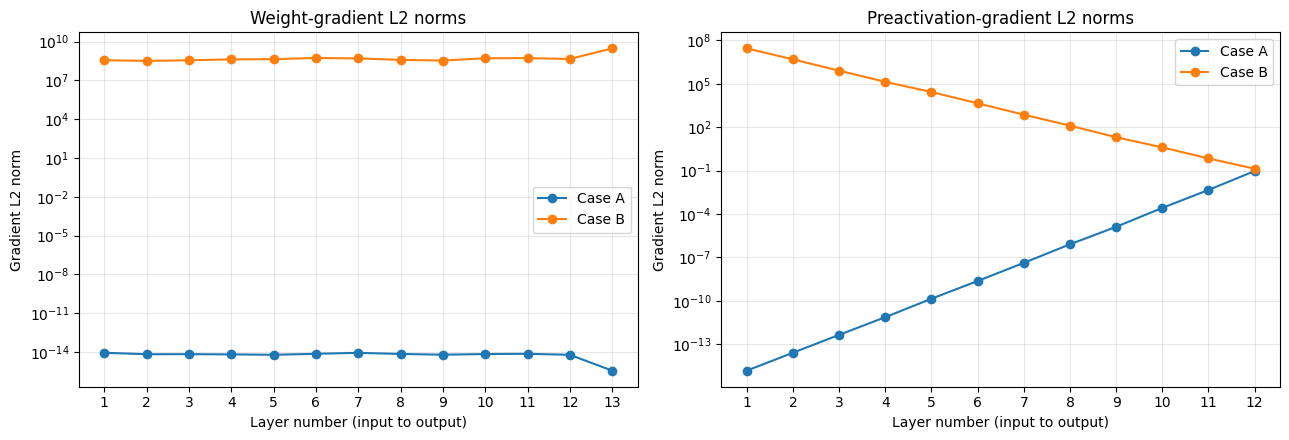

Before backward, .grad: None
After backward, gradient norm: 8.730728576352657e-15
Did the weight change? False


In [4]:

def diagnose(model):
    model.zero_grad()

    logits, preactivations = model(x_probe, return_trace=True)

    for z in preactivations:
        z.retain_grad()

    loss = nn.functional.cross_entropy(logits, y_probe)

    if not torch.isfinite(loss).item():
        return loss.item(), [], []

    loss.backward()

    def norm(t):
        if t is None:
            return float("nan")
        return torch.linalg.vector_norm(
            t.detach().double().flatten()
        ).item()

    weight_grad_norms = [
        norm(layer.weight.grad) for layer in model.hidden
    ]
    weight_grad_norms.append(norm(model.output.weight.grad))

    preactivation_grad_norms = [
        norm(z.grad) for z in preactivations
    ]

    return loss.item(), weight_grad_norms, preactivation_grad_norms


# Run diagnostics for both initializations
results = {}

for name, initializer in cases.items():
    model = build_case(initializer)
    results[name] = diagnose(model)

    loss, w_norms, z_norms = results[name]

    print(f"Case {name}")
    print(f"Initial loss: {loss:.6g}")
    print(f"First hidden preactivation grad: {z_norms[0]:.6e}")
    print(f"Last hidden preactivation grad: {z_norms[-1]:.6e}")
    print()


# Plot gradient norms
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, (loss, w_norms, z_norms) in results.items():
    axes[0].plot(
        range(1, N_HIDDEN + 2),
        w_norms,
        marker="o",
        label=f"Case {name}"
    )

    axes[1].plot(
        range(1, N_HIDDEN + 1),
        z_norms,
        marker="o",
        label=f"Case {name}"
    )

axes[0].set_title("Weight-gradient L2 norms")
axes[1].set_title("Preactivation-gradient L2 norms")

for ax in axes:
    ax.set_xlabel("Layer number (input to output)")
    ax.set_ylabel("Gradient L2 norm")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_xticks(range(1, N_HIDDEN + 2))
axes[1].set_xticks(range(1, N_HIDDEN + 1))

plt.tight_layout()
plt.show()


# Verify backward() does not update weights
model = build_case(cases["A"])

weight = model.hidden[0].weight
weight_before = weight.detach().clone()

print("Before backward, .grad:", weight.grad)

logits = model(x_probe)
loss = nn.functional.cross_entropy(logits, y_probe)
loss.backward()

print("After backward, gradient norm:",
      weight.grad.norm().item())

print(
    "Did the weight change?",
    not torch.equal(weight_before, weight.detach())
)


**Answer briefly:**

1. Which case shows vanishing gradient flow and which shows exploding gradient flow? Cite the first and last hidden preactivation-gradient norms from each run.
2. What did `backward()` change? What does `optimizer.step()` do instead?

**1. Which case shows vanishing gradient flow and which shows exploding gradient flow?**

Case A (std = 0.01) shows vanishing gradients. The first hidden layer has a preactivation-gradient norm of 1.504591e-15, while the last hidden layer has 9.244010e-02. This shows that gradients become extremely small as they propagate backward through the network, making it difficult for earlier layers to learn.

Case B (std = 1.0) shows exploding gradients. The first hidden layer has a preactivation-gradient norm of 2.749272e+07, while the last hidden layer has 1.348903e-01. This indicates that gradients grow dramatically during backpropagation, potentially causing unstable weight updates and training.

**2. What did `backward()` change? What does `optimizer.step()` do instead?**

`backward()` computes gradients of the loss with respect to the model parameters and stores them in their `.grad` attributes. It does not modify the weights themselves, as confirmed by our experiment (`Did the weight change? False`).

`optimizer.step()` uses the computed gradients and the optimizer's update rule (SGD with momentum in this challenge) to update the model parameters, allowing the network to learn.


## 3. Repair the initialization

Before coding, propose a hidden-weight initialization that should address both failures. Explain how the number of incoming connections and ReLU influence your choice. You may consult the lecture slides and PyTorch initialization documentation.

Change **only hidden-weight initialization**. Keep hidden biases zero and all other settings fixed. Do not add clipping, normalization, skip connections, or a new activation.

Implement `repair_hidden(model)`. Diagnose a fresh repaired model and add its curves to the same two-panel figure. If your first attempt fails, keep that result and revise your initialization.

**Prediction and reasoning:** I propose using He (Kaiming) initialization to address both vanishing and exploding gradients. This method scales the weight standard deviation based on the number of incoming connections (fan-in):

$\sigma = \sqrt{\frac{2}{n_{\text{in}}}}$



Since our network uses ReLU, which sets negative activations to zero, this scaling helps maintain more stable activation and gradient magnitudes across layers. I expect the repaired model to show more consistent preactivation-gradient norms compared to cases A and B, improving training stability.


Case Repair (Kaiming Initialization)
Initial loss: 2.35105
First hidden preactivation grad: 8.164119e-02
Last hidden preactivation grad: 9.345903e-02


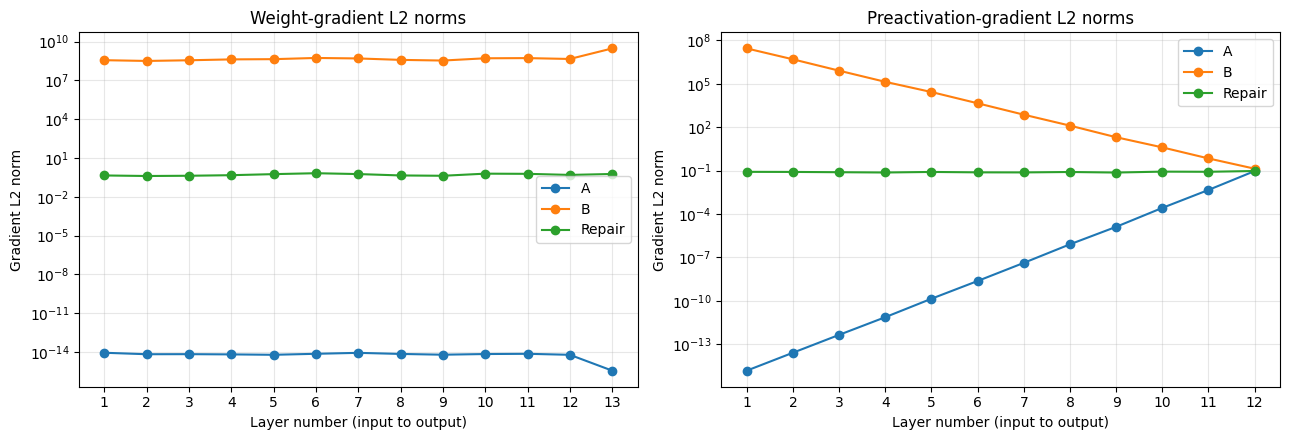

In [5]:

def repair_hidden(model):
    for layer in model.hidden:
        nn.init.kaiming_normal_(
            layer.weight,
            mode="fan_in",
            nonlinearity="relu"
        )
        nn.init.zeros_(layer.bias)


# Diagnose repaired model
repair_model = build_case(repair_hidden)
repair_results = diagnose(repair_model)

repair_loss, repair_w_norms, repair_z_norms = repair_results

print("Case Repair (Kaiming Initialization)")
print(f"Initial loss: {repair_loss:.6g}")
print(f"First hidden preactivation grad: {repair_z_norms[0]:.6e}")
print(f"Last hidden preactivation grad: {repair_z_norms[-1]:.6e}")


# Compare all three initializations
all_results = {
    "A": results["A"],
    "B": results["B"],
    "Repair": repair_results
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, (loss, w_norms, z_norms) in all_results.items():
    axes[0].plot(
        range(1, N_HIDDEN + 2),
        w_norms,
        marker="o",
        label=name
    )

    axes[1].plot(
        range(1, N_HIDDEN + 1),
        z_norms,
        marker="o",
        label=name
    )

axes[0].set_title("Weight-gradient L2 norms")
axes[1].set_title("Preactivation-gradient L2 norms")

for ax in axes:
    ax.set_xlabel("Layer number (input to output)")
    ax.set_ylabel("Gradient L2 norm")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_xticks(range(1, N_HIDDEN + 2))
axes[1].set_xticks(range(1, N_HIDDEN + 1))

plt.tight_layout()
plt.show()


## 4. Check whether learning improves

Train **three fresh models: A, B, and your repaired initialization**, using the supplied seed and loader, SGD (`lr=0.01`, `momentum=0.9`), and 25 epochs.

Write the training loop: clear gradients, forward, cross-entropy, backward, update. At epoch 0 and after each complete epoch, evaluate full training/validation loss and validation accuracy under `torch.no_grad()`. Keep histories as Python numbers.

Stop and label a run if its loss, gradients, parameters, or evaluation metrics become `NaN`/`inf`. Record where it stopped and keep its earlier results. Do not continue that run or replace failed values with zeros.

Produce:
- A **three-row table** with status, completed epochs, final training/validation loss, and validation accuracy. Mark failed-run final metrics as unavailable.
- Training/validation loss curves for the three cases. Show extreme losses separately if needed and label failure points.
- Test loss and accuracy for your final repaired model, evaluated once after completing your initialization choice using training/validation evidence.

No additional seeds, gradient-history plots, or activation-statistic plots are required.



Training Case A...
Status: Completed
Completed epochs: 25

Training Case B...
Status: Failed: non-finite loss
Completed epochs: 0
Stopped during epoch: 1

Training Case Repair...
Status: Completed
Completed epochs: 25

TRAINING COMPARISON
Case       Status                                Epochs    Train Loss      Val Loss        Val Acc   
A          Completed                             25        2.302461        2.302627        10.03%    
B          Failed: non-finite loss               0         Unavailable     Unavailable     Unavailable
Repair     Completed                             25        0.022775        0.227310        94.99%    


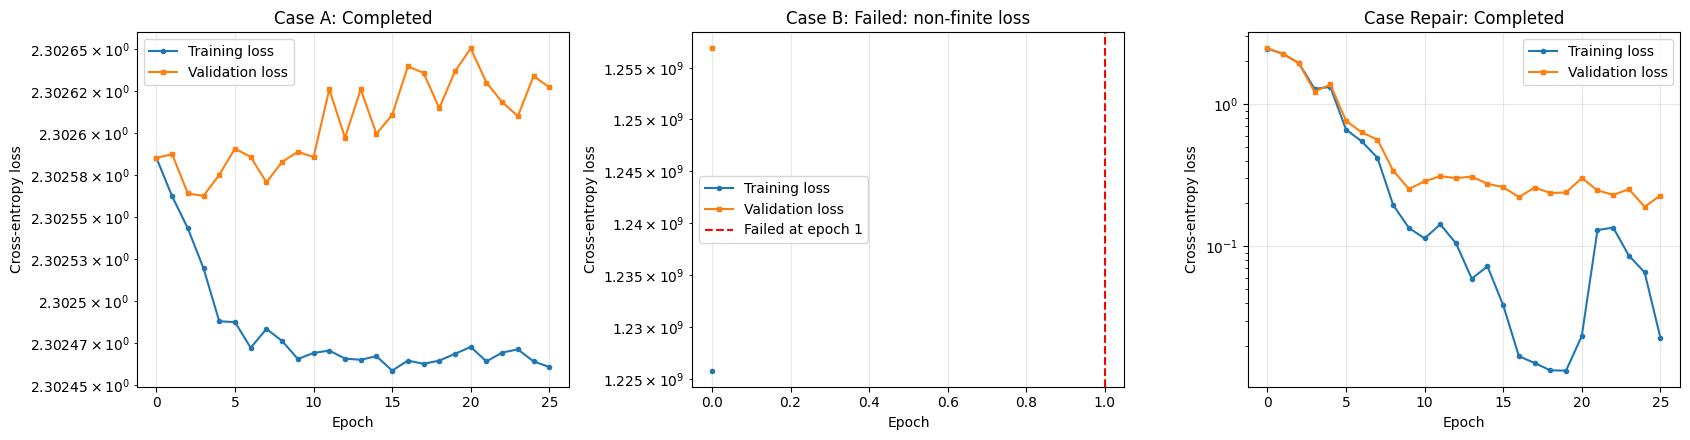


FINAL REPAIRED MODEL - TEST RESULTS
Test loss: 0.174810
Test accuracy: 95.56%


In [6]:

def evaluate(model, X_data, y_data):
    model.eval()

    with torch.no_grad():
        logits = model(X_data)
        loss = nn.functional.cross_entropy(logits, y_data)
        accuracy = (logits.argmax(dim=1) == y_data).float().mean()

    return loss.item(), accuracy.item()


def train_case(initializer):
    model = build_case(initializer)
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LR,
        momentum=MOMENTUM
    )
    loader = make_train_loader()

    history = {
        "epochs": [],
        "train_loss": [],
        "val_loss": [],
        "val_acc": []
    }

    status = "Completed"
    stopped_at = None
    completed_epochs = 0

    def record_metrics(epoch):
        train_loss, _ = evaluate(model, X_train, y_train)
        val_loss, val_acc = evaluate(model, X_val, y_val)

        values = [train_loss, val_loss, val_acc]

        if not all(math.isfinite(v) for v in values):
            return False

        history["epochs"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        return True

    # Evaluate before training (epoch 0)
    if not record_metrics(0):
        status = "Failed: non-finite initial metrics"
        stopped_at = 0

    if stopped_at is None:
        for epoch in range(1, EPOCHS + 1):
            model.train()
            failure = None

            for xb, yb in loader:
                optimizer.zero_grad()

                logits = model(xb)
                loss = nn.functional.cross_entropy(logits, yb)

                # Check loss
                if not torch.isfinite(loss).item():
                    failure = "non-finite loss"
                    break

                loss.backward()

                # Check gradients
                if any(
                    p.grad is not None
                    and not torch.isfinite(p.grad).all().item()
                    for p in model.parameters()
                ):
                    failure = "non-finite gradients"
                    break

                optimizer.step()

                # Check updated parameters
                if any(
                    not torch.isfinite(p).all().item()
                    for p in model.parameters()
                ):
                    failure = "non-finite parameters"
                    break

            if failure is not None:
                status = f"Failed: {failure}"
                stopped_at = epoch
                break

            # Evaluate after each complete epoch
            if not record_metrics(epoch):
                status = "Failed: non-finite evaluation metrics"
                stopped_at = epoch
                break

            completed_epochs = epoch

    return {
        "model": model,
        "history": history,
        "status": status,
        "stopped_at": stopped_at,
        "completed_epochs": completed_epochs
    }


# Train all three models
training_results = {}

initializers = {
    "A": cases["A"],
    "B": cases["B"],
    "Repair": repair_hidden
}

for name, initializer in initializers.items():
    print(f"\nTraining Case {name}...")

    result = train_case(initializer)
    training_results[name] = result

    print("Status:", result["status"])
    print("Completed epochs:", result["completed_epochs"])

    if result["stopped_at"] is not None:
        print("Stopped during epoch:", result["stopped_at"])


# Three-row comparison table
print("\n" + "=" * 105)
print("TRAINING COMPARISON")
print("=" * 105)

print(
    f"{'Case':<10} {'Status':<37} {'Epochs':<9} "
    f"{'Train Loss':<15} {'Val Loss':<15} {'Val Acc':<10}"
)

for name, result in training_results.items():
    h = result["history"]

    if result["status"] == "Completed":
        train_loss = f"{h['train_loss'][-1]:.6f}"
        val_loss = f"{h['val_loss'][-1]:.6f}"
        val_acc = f"{h['val_acc'][-1] * 100:.2f}%"
    else:
        train_loss = "Unavailable"
        val_loss = "Unavailable"
        val_acc = "Unavailable"

    print(
        f"{name:<10} {result['status']:<37} "
        f"{result['completed_epochs']:<9} "
        f"{train_loss:<15} {val_loss:<15} {val_acc:<10}"
    )


# Plot loss curves for each case
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, (name, result) in zip(axes, training_results.items()):
    h = result["history"]

    ax.plot(
        h["epochs"],
        h["train_loss"],
        marker="o",
        markersize=3,
        label="Training loss"
    )

    ax.plot(
        h["epochs"],
        h["val_loss"],
        marker="s",
        markersize=3,
        label="Validation loss"
    )

    if result["stopped_at"] is not None:
        ax.axvline(
            result["stopped_at"],
            color="red",
            linestyle="--",
            label=f"Failed at epoch {result['stopped_at']}"
        )

    ax.set_title(f"Case {name}: {result['status']}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


# Evaluate final repaired model on the test set ONCE
repaired = training_results["Repair"]

if repaired["status"] == "Completed":
    test_loss, test_acc = evaluate(
        repaired["model"], X_test, y_test
    )

    if math.isfinite(test_loss) and math.isfinite(test_acc):
        print("\nFINAL REPAIRED MODEL - TEST RESULTS")
        print(f"Test loss: {test_loss:.6f}")
        print(f"Test accuracy: {test_acc * 100:.2f}%")
    else:
        print("\nRepaired model test metrics are non-finite.")
else:
    print("\nRepaired model failed; test evaluation unavailable.")


**Conclusion (3–5 sentences):** What failed in A and B, what did you change, and which gradient measurements and learning results show whether it worked?

The experiments demonstrate how weight initialization affects gradient flow and training performance in deep neural networks.

Case A (std = 0.01) suffered from vanishing gradients and achieved only 10.03% validation accuracy after 25 epochs.

Case B (std = 1.0) experienced exploding gradients and failed during the first epoch due to a non-finite loss. He (Kaiming) initialization stabilized gradient magnitudes across all 12 hidden layers, allowing the model to learn effectively and achieve 95% validation accuracy.

The repaired model also achieved 95.56% test accuracy with a test loss of 0.174810, demonstrating that the improvement generalized to unseen data. Overall, these results highlight the importance of proper weight initialization for stable training in deep ReLU networks.

**Submit:** Complete all TODOs, restart the kernel, run all cells, and save with outputs as `ARTE4110U_Initialization_StudentID.ipynb`. Expected numerical failures must be handled by your code. Submit individually on Canvas.

**AI disclosure:** Codex was used to validate output and results.

**References:** [Dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), [backward](https://docs.pytorch.org/docs/stable/generated/torch.Tensor.backward.html), [retain_grad](https://docs.pytorch.org/docs/stable/generated/torch.Tensor.retain_grad.html), [initialization API](https://docs.pytorch.org/docs/stable/nn.init.html).
